## Гипергеометрическое распределение



In [2]:
!pip3 install numpy scipy matplotlib

  Using cached scipy-1.18.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
Using cached scipy-1.18.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (35.3 MB)


In [1]:
import numpy as np
from scipy.stats import binom, norm, poisson

In [2]:
def binom_exact_prob(k, n, p):
    return binom.pmf(k, n, p)

def binom_poisson_prob(k, n, p):
    return poisson.pmf(k, mu=n * p)

def binom_moivre_laplace(k, n, p):
    mu = n * p
    sigma = np.sqrt(n * p * (1 - p))
    return norm.pdf(k, loc=mu, scale=sigma)

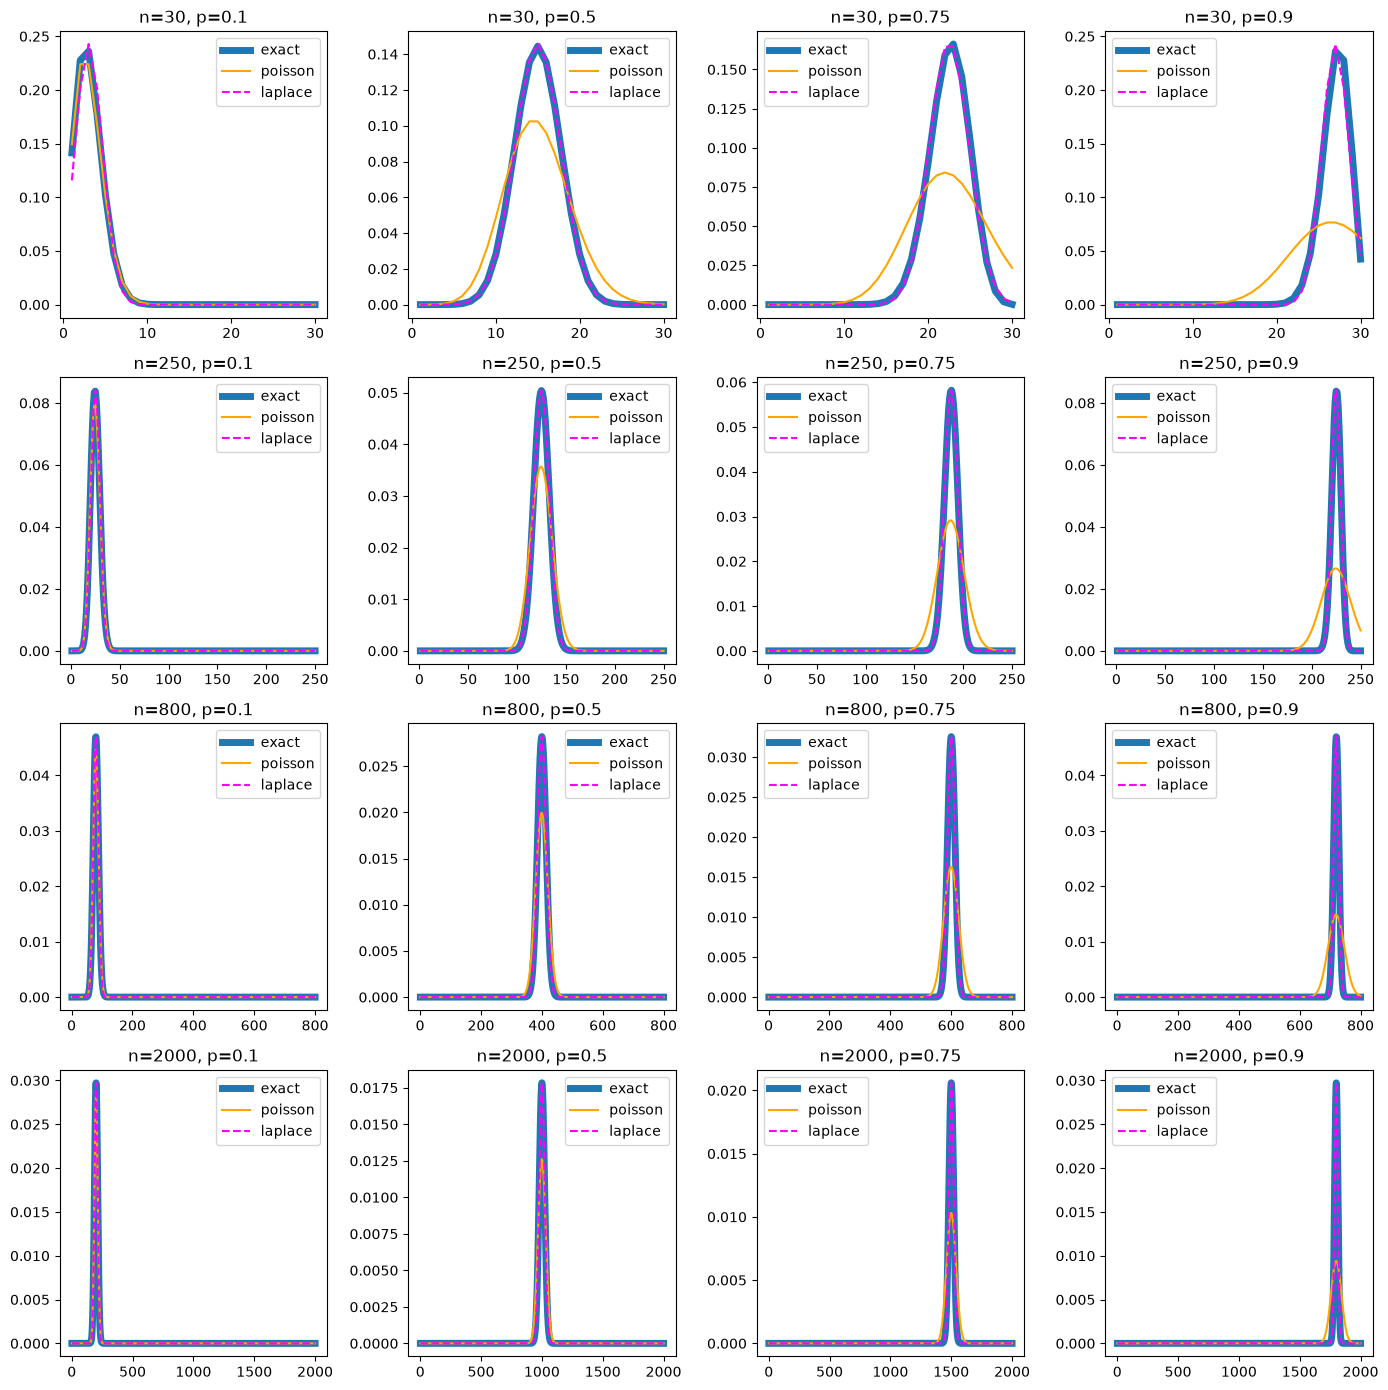

In [21]:
import matplotlib.pyplot as plt

ns = [30, 250, 800, 2000]
ps = [0.1, 0.5, 0.75, 0.9]

fig, axes = plt.subplots(len(ns), len(ps), figsize=(14, 14))

for i, n in enumerate(ns):
    for j, p in enumerate(ps):
        ax = axes[i, j]
        ks = np.arange(1, n + 1)

        ax.plot(ks, binom_exact_prob(ks, n, p), label="exact", linewidth=5)
        ax.plot(ks, binom_poisson_prob(ks, n, p), color='orange', label="poisson")
        ax.plot(ks, binom_moivre_laplace(ks, n, p), color='magenta', label="laplace", linestyle="--")

        ax.set_title(f"n={n}, p={p}")
        ax.legend()

plt.tight_layout()
plt.show()